# Evaluación Práctica E3: Modelado Predictivo de Riesgo Crediticio

---

## Descripción y Contexto del Negocio

Una institución financiera recibe solicitudes de préstamos hipotecarios y necesita evaluar de manera automatizada el riesgo de incumplimiento o impago de cada solicitante mediante un modelo de clasificación supervisada basado en árboles de decisión.

La variable objetivo es **`Riesgo_Impago`**:
- **`0` (Cumplidor):** Crédito pagado sin mora.
- **`1` (Impago / Default):** El cliente incurre en incumplimiento de pago del préstamo hipotecario.

### Impacto Financiero de los Errores de Clasificación
En el negocio hipotecario existe una fuerte asimetría en los costos de error:
- Falso Positivo (FP — Clasificar a un cliente cumplidor como riesgo de impago y denegarle el crédito):

  Implica un costo de oportunidad de `$200.000` por pérdida de ganancias en intereses.
- Falso Negativo (FN — Clasificar a un cliente en riesgo como cumplidor y otorgarle el crédito):

  Implica una pérdida financiera directa de `$1.500.000` por impago del capital (un error 7,5 veces más costoso que el Falso Positivo).

### Diccionario de Datos
| Variable | Tipo de Dato | Descripción de Negocio |
| :--- | :--- | :--- |
| **`Ingreso_Anual`** | Continua | Ingreso total bruto al año expresado en dólares (`$`). |
| **`Monto_Prestamo`** | Continua | Monto total de la hipoteca que el cliente está solicitando (`$`). |
| **`Puntaje_Credito`** | Continua | Indicador de solvencia financiera previa (escala `300` a `850` puntos). |
| **`Relacion_Deuda_Ingreso`** | Continua | Porcentaje del ingreso mensual de la persona comprometido en deudas (`DTI %`). |
| **`Riesgo_Impago` *(Target)*** | Binaria (`0`/`1`) | `0`: Crédito pagado sin mora \| `1`: Incumplimiento/Impago del crédito. |

---

## Requisitos de Software

Este notebook fue desarrollado para Python 3.10+ utilizando las siguientes bibliotecas estándar de ciencia de datos:
- `pandas`
- `numpy`
- `matplotlib`
- `seaborn`
- `scikit-learn`

In [ ]:
!wget https://raw.githubusercontent.com/benjaminqq-12/Inteligencia-Artificial-2026-2/refs/heads/main/E3-Clasificaci%C3%B3n/riesgo_crediticio.csv

--2026-11-04 21:01:18--  https://raw.githubusercontent.com/benjaminqq-12/Inteligencia-Artificial-2026-2/refs/heads/main/E3-Clasificaci%C3%B3n/riesgo_crediticio.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 953627 (931K) [text/plain]
Saving to: ‘riesgo_crediticio.csv’

riesgo_crediticio.c 100%[===================>] 931.28K  --.-KB/s    in 0.03s   

2026-11-04 21:01:18 (35.7 MB/s) - ‘riesgo_crediticio.csv’ saved [953627/953627]



In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    auc,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Fase 1: Diagnóstico y Calidad de Datos

En esta primera fase se carga el conjunto de datos `riesgo_crediticio.csv` y se realiza una revisión completa de la calidad de los datos:
1. **Estructura y tipos de datos** (`.info()`, `.head()`, `.describe()`).
2. **Identificación de valores nulos y registros duplicados.**
3. **Verificación de inconsistencias lógicas de negocio** (ingresos o préstamos $\le 0$, puntajes crediticios fuera del rango $[300, 850]$ o porcentajes DTI fuera de $[0, 100]$).
4. **Detección estadística y gráfica de valores atípicos (*outliers*)** mediante el método del Rango Intercuartílico ($IQR$).
5. **Análisis del desbalance de la variable objetivo (`Riesgo_Impago`)** y correlaciones con las variables predictoras.

In [ ]:
# Carga del conjunto de datos
data = pd.read_csv("riesgo_crediticio.csv")
data.head()

,Unnamed: 0,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
0,0,39785.55,85246.38,694.0,70.00,0
1,1,69773.95,244260.00,622.0,10.65,0
2,2,127770.68,209310.35,780.0,42.70,0
3,3,16799.80,213059.98,741.0,48.04,0
4,4,70229.83,219523.13,714.0,25.58,0


In [ ]:
# Revisión general de dimensiones, tipos de datos y memoria
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              25000 non-null  int64  
 1   Ingreso_Anual           25000 non-null  float64
 2   Monto_Prestamo          25000 non-null  float64
 3   Puntaje_Credito         25000 non-null  float64
 4   Relacion_Deuda_Ingreso  25000 non-null  float64
 5   Riesgo_Impago           25000 non-null  int64  
dtypes: float64(4), int64(2)
memory usage: 1.1 MB


In [ ]:
# Estadísticos descriptivos generales del conjunto de datos
data.describe().round(2)

,Unnamed: 0,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
count,25000.00,25000.00,25000.00,25000.00,25000.00,25000.00
mean,12499.50,55824.44,220162.89,680.03,24.03,0.07
std,7217.02,29804.90,60059.30,59.78,13.62,0.26
min,0.00,7832.12,50000.00,457.00,5.00,0.00
25%,6249.75,35051.32,179438.08,640.00,13.79,0.00
50%,12499.50,49234.68,220241.47,680.00,21.45,0.00
75%,18749.25,68923.52,261003.36,721.00,31.38,0.00
max,24999.00,348135.55,451784.21,850.00,70.00,1.00


In [ ]:
# Auditoría de calidad: valores nulos, duplicados e inconsistencias lógicas de negocio
print("--- 1. VALORES NULOS POR COLUMNA ---")
print(data.isnull().sum())

print("\n--- 2. REGISTROS DUPLICADOS ---")
print(f"Filas completamente duplicadas: {data.duplicated().sum()}")
print(f"Duplicados en variables de negocio (sin Unnamed: 0): {data.drop(columns=['Unnamed: 0']).duplicated().sum()}")

print("\n--- 3. VERIFICACIÓN DE INCONSISTENCIAS LÓGICAS DE NEGOCIO ---")
print(f"Ingreso_Anual <= 0: {(data['Ingreso_Anual'] <= 0).sum()} registros")
print(f"Monto_Prestamo <= 0: {(data['Monto_Prestamo'] <= 0).sum()} registros")
print(f"Puntaje_Credito fuera de rango [300, 850]: {((data['Puntaje_Credito'] < 300) | (data['Puntaje_Credito'] > 850)).sum()} registros")
print(f"Relacion_Deuda_Ingreso (DTI %) fuera de [0, 100]: {((data['Relacion_Deuda_Ingreso'] < 0) | (data['Relacion_Deuda_Ingreso'] > 100)).sum()} registros")
print(f"Valores de Riesgo_Impago distintos de {{0, 1}}: {(~data['Riesgo_Impago'].isin([0, 1])).sum()} registros")

--- 1. VALORES NULOS POR COLUMNA ---
Unnamed: 0                0
Ingreso_Anual             0
Monto_Prestamo            0
Puntaje_Credito           0
Relacion_Deuda_Ingreso    0
Riesgo_Impago             0
dtype: int64

--- 2. REGISTROS DUPLICADOS ---
Filas completamente duplicadas: 0
Duplicados en variables de negocio (sin Unnamed: 0): 0

--- 3. VERIFICACIÓN DE INCONSISTENCIAS LÓGICAS DE NEGOCIO ---
Ingreso_Anual <= 0: 0 registros
Monto_Prestamo <= 0: 0 registros
Puntaje_Credito fuera de rango [300, 850]: 0 registros
Relacion_Deuda_Ingreso (DTI %) fuera de [0, 100]: 0 registros
Valores de Riesgo_Impago distintos de {0, 1}: 0 registros


### Detección Estadística y Visual de Outliers

A continuación, se aplica la regla del Rango Intercuartílico ($IQR = Q_3 - Q_1$) con límites $[Q_1 - 1,5 \times IQR,\; Q_3 + 1,5 \times IQR]$ y gráficos de caja (*boxplots*) para identificar valores extremos en las variables numéricas:

In [ ]:
# Cuantificación de outliers mediante el método del Rango Intercuartílico (IQR)
num_cols = ["Ingreso_Anual", "Monto_Prestamo", "Puntaje_Credito", "Relacion_Deuda_Ingreso"]
outlier_rows = []

for col in num_cols:
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n_out = int(((data[col] < low) | (data[col] > high)).sum())
    pct_out = (n_out / len(data)) * 100
    outlier_rows.append({
        "Variable": col,
        "Q1 (25%)": round(q1, 2),
        "Mediana (50%)": round(data[col].median(), 2),
        "Q3 (75%)": round(q3, 2),
        "IQR": round(iqr, 2),
        "Límite Inferior": round(low, 2),
        "Límite Superior": round(high, 2),
        "N° Outliers": n_out,
        "% Outliers": round(pct_out, 2)
    })

outlier_df = pd.DataFrame(outlier_rows)
outlier_df

,Variable,Q1 (25%),Mediana (50%),Q3 (75%),IQR,Límite Inferior,Límite Superior,N° Outliers,% Outliers
0,Ingreso_Anual,35051.32,49234.68,68923.52,33872.20,-15756.99,119731.82,976,3.90
1,Monto_Prestamo,179438.08,220241.47,261003.36,81565.28,57090.15,383351.29,157,0.63
2,Puntaje_Credito,640.00,680.00,721.00,81.00,518.50,842.50,167,0.67
3,Relacion_Deuda_Ingreso,13.79,21.45,31.38,17.60,-12.60,57.78,663,2.65


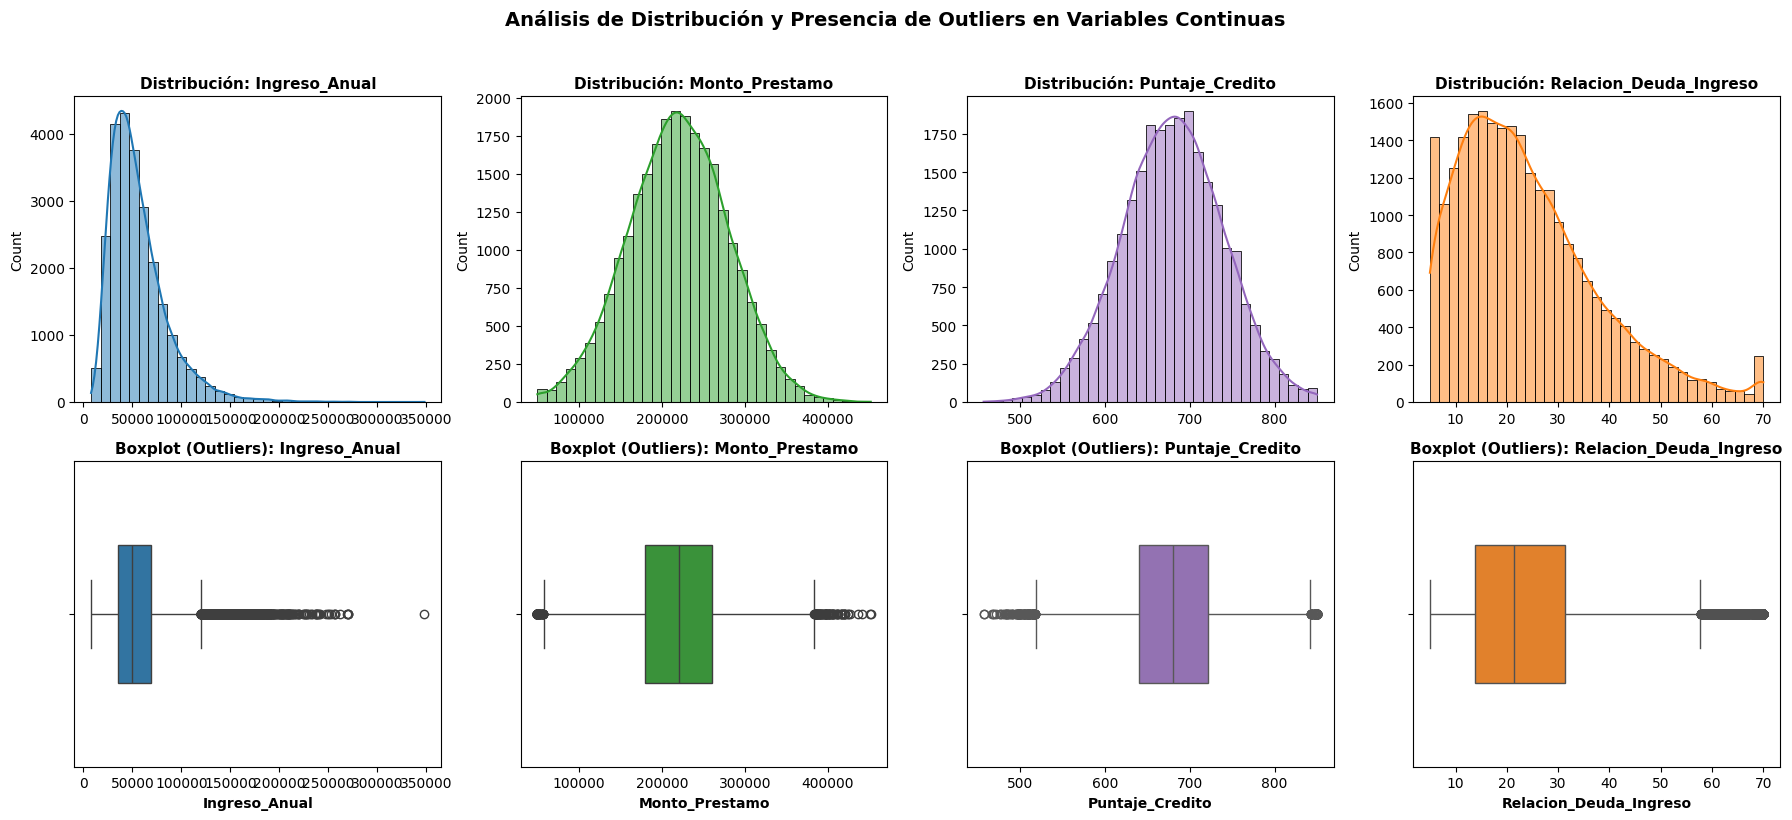

In [ ]:
# Visualización de la distribución y presencia de outliers (Histogramas y Boxplots)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
colors_eda = ["#1f77b4", "#2ca02c", "#9467bd", "#ff7f0e"]

for idx, col in enumerate(num_cols):
    sns.histplot(data[col], kde=True, ax=axes[0, idx], color=colors_eda[idx], bins=35)
    axes[0, idx].set_title(f"Distribución: {col}", fontsize=11, fontweight="bold")
    axes[0, idx].set_xlabel("")

    sns.boxplot(x=data[col], ax=axes[1, idx], color=colors_eda[idx], width=0.45)
    axes[1, idx].set_title(f"Boxplot (Outliers): {col}", fontsize=11, fontweight="bold")
    axes[1, idx].set_xlabel(col, fontsize=10, fontweight="bold")

plt.suptitle("Análisis de Distribución y Presencia de Outliers en Variables Continuas", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### Análisis del Desbalance de la Variable Objetivo (`Riesgo_Impago`)

Ahora se revisará la proporción y frecuencia de cada categoría de la variable objetivo para cuantificar el nivel de desbalance del problema:

In [ ]:
# Revisa la proporción de la variable objetivo
target = "Riesgo_Impago"
data[target].value_counts(normalize=True)

,proportion
Riesgo_Impago,
0,0.92844
1,0.07156


In [ ]:
# Revisa la frecuencia absoluta de la variable objetivo
data[target].value_counts()

,count
Riesgo_Impago,
0,23211
1,1789


In [ ]:
target_names = ["Cumplidor (0)", "Impago (1)"]

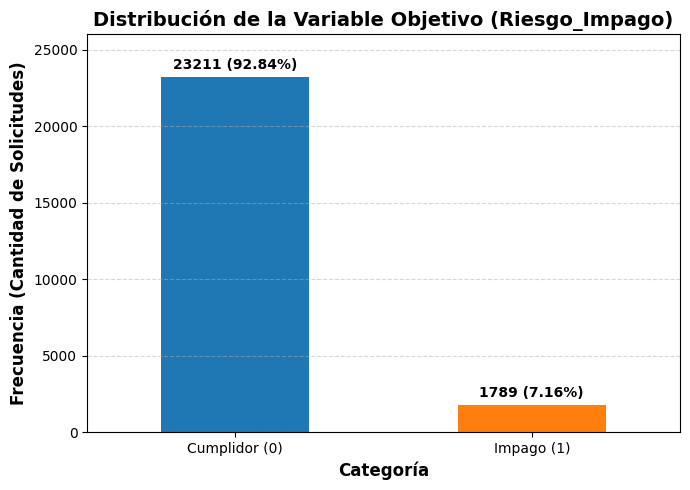

In [ ]:
# Gráfica de la distribución de la variable objetivo
plt.figure(figsize=(7, 5))
counts_target = data[target].value_counts()
counts_target.plot(kind="bar", color=["#1f77b4", "#ff7f0e"])
plt.title("Distribución de la Variable Objetivo (Riesgo_Impago)", fontsize=14, fontweight="bold")
plt.xlabel("Categoría", fontsize=12, fontweight="bold")
plt.ylabel("Frecuencia (Cantidad de Solicitudes)", fontsize=12, fontweight="bold")

# Agregar etiquetas de frecuencia y porcentaje sobre cada barra
for i, value in enumerate(counts_target):
    pct = value / len(data) * 100
    plt.text(i, value + 300, f"{value} ({pct:.2f}%)", ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.xticks(ticks=[0, 1], labels=target_names, rotation=0)
plt.ylim(0, max(counts_target) * 1.12)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

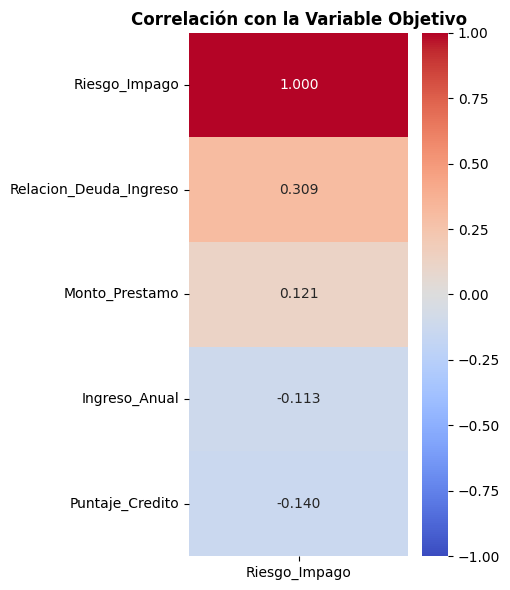

In [ ]:
# Calcula la correlación de las variables predictoras con la variable objetivo
correlation_with_target = data.drop(columns=["Unnamed: 0"]).corr()[[target]].sort_values(by=target, ascending=False)

plt.figure(figsize=(5, 6))
sns.heatmap(
    correlation_with_target,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlación con la Variable Objetivo", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### Conclusiones del Diagnóstico de Calidad de Datos (Fase 1)

1. **Integridad y Consistencia Lógica:** El conjunto de datos cuenta con **25.000 registros y 6 columnas**, sin valores nulos ni filas duplicadas. Tampoco se encontraron inconsistencias lógicas de negocio: todos los ingresos anuales y montos de préstamo son positivos y se encuentran dentro de los rangos válidos.
2. **Columna Irrelevante (`Unnamed: 0`):** Corresponde únicamente a un índice correlativo (`0` a `24.999`) que no aporta información sobre los clientes. Por ello, se tomó la decisión de eliminarla antes del modelado para evitar ruido y memorización (*overfitting*).
3. **Presencia de Outliers Reales de Negocio:** Se identificaron valores atípicos principalmente en **`Ingreso_Anual` (976 casos; 3,90%)**, correspondiente a solicitantes de altos ingresos, y en **`Relacion_Deuda_Ingreso` (663 casos; 2,65%)**, asociado a clientes con alto nivel de endeudamiento, además de proporciones menores en `Puntaje_Credito` (0,67%) y `Monto_Prestamo` (0,63%). Desde el punto de vista financiero, estos registros **no son errores de digitación**, sino perfiles reales de clientes (de hecho, la relación deuda-ingreso es la variable más correlacionada con el impago, con $r = 0,309$). Por esta razón, **se decidió no eliminarlos**; además, dado que los árboles de decisión dividen por umbrales de orden y no por distancias, **no se aplica escalado ni estandarización**, conservando las unidades originales del negocio (dólares, puntos y porcentajes) para que las reglas del árbol sean directamente interpretables.
4. **Fuerte Desbalance de la Variable Objetivo:** Se observa un marcado desbalance hacia la clase mayoritaria: **23.211 clientes cumplidores (92,84%)** frente a solo **1.789 clientes en impago (7,16%)**, lo que equivale a una proporción aproximada de **13:1**. A partir de este hallazgo, se tomaron las siguientes decisiones:
   - Utilizar **división estratificada** (`stratify=y`) tanto en la separación de entrenamiento/prueba como en la validación cruzada.
   - Evaluar el ajuste de pesos por clase (`class_weight="balanced"`) en el árbol de decisión.
   - Descartar el *Accuracy* (exactitud global) como métrica principal y seleccionar **Recall (Sensibilidad)** y **F1-Score** sobre la clase `Impago (1)` para evaluar el modelo.

# Fase 2: Limpieza y Tratamiento de Datos

Para asegurar un flujo de preprocesamiento ordenado y evitar la fuga de datos (*data leakage*) entre el conjunto de entrenamiento y el de prueba (así como dentro de la validación cruzada), se implementará lo siguiente:
1. **Eliminación de columnas irrelevantes (`Unnamed: 0`):** Se descarta del conjunto de datos por ser solo un identificador de fila.
2. **Encapsulamiento en un `ColumnTransformer` y `Pipeline` de Scikit-Learn:**
   - **`SimpleImputer(strategy="median")`:** Se integra una imputación preventiva mediante la mediana (calculada exclusivamente con los datos de entrenamiento) para resguardar el flujo ante eventuales valores nulos en producción sin verse afectada por valores extremos.
   - **Sin escalado ni estandarización de variables:** Se tomó la decisión técnica de **no escalar las variables numéricas** antes del `DecisionTreeClassifier`, ya que los árboles de decisión son invariantes a la escala y de esta manera los nodos del árbol conservan los montos en dólares, puntajes (`300-850`) y porcentajes (`DTI %`) reales del negocio.

In [ ]:
# 1. Elimina la columna índice sin aporte predictivo para el modelo
if "Unnamed: 0" in data.columns:
    data.drop(["Unnamed: 0"], axis=1, inplace=True)

# 2. Separa las variables predictoras (X) y la variable objetivo (y)
X = data.drop(target, axis=1)
y = data[target]

# 3. Define el Pipeline de preprocesamiento numérico estructurado con ColumnTransformer (sin escalar para conservar unidades reales en el árbol)
numeric_features = ["Ingreso_Anual", "Monto_Prestamo", "Puntaje_Credito", "Relacion_Deuda_Ingreso"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features)
    ],
    remainder="drop"
)

print("Columnas predictoras integradas en el Pipeline (en sus unidades originales):", numeric_features)

Columnas predictoras integradas en el Pipeline: ['Ingreso_Anual', 'Monto_Prestamo', 'Puntaje_Credito', 'Relacion_Deuda_Ingreso']


# Fase 3: Construcción del Modelo

En esta etapa se estructura el entrenamiento y la optimización del clasificador en tres pasos:
1. **División Train/Test:** Se separa el 80% de los datos para entrenamiento (`20.000` registros) y el 20% para prueba (`5.000` registros) utilizando muestreo estratificado (`stratify=y`) y semilla fija (`random_state=29`) antes de aplicar cualquier transformación.
2. **Modelo Línea Base (*Baseline*):** Se entrena un `Pipeline` con un `DecisionTreeClassifier` utilizando sus hiperparámetros por defecto (sin límite de profundidad), con el fin de contar con un punto de comparación inicial y verificar si ocurre memorización (*overfitting*).
3. **Modelo Optimizado:** Se implementa una búsqueda exhaustiva con `GridSearchCV` y validación cruzada estratificada de 5 pliegues (`StratifiedKFold`), ajustando **5 hiperparámetros explícitos** (`criterion`, `max_depth`, `min_samples_split`, `min_samples_leaf`, `class_weight`) para mejorar la generalización y la detección de impagos.

In [ ]:
# 1. División estratificada del conjunto de datos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=29, stratify=y
)

print(f"Dimensiones X_train: {X_train.shape} | Dimensiones X_test: {X_test.shape}")
print(f"Proporción clase Impago (1) en Train: {y_train.mean():.5f} ({y_train.sum()} de {len(y_train)})")
print(f"Proporción clase Impago (1) en Test:  {y_test.mean():.5f} ({y_test.sum()} de {len(y_test)})")

Dimensiones X_train: (20000, 4) | Dimensiones X_test: (5000, 4)
Proporción clase Impago (1) en Train: 0.07155 (1431 de 20000)
Proporción clase Impago (1) en Test:  0.07160 (358 de 5000)


## 3.1 Modelo Línea Base (*Baseline*)

Se construye y entrena un árbol de decisión con su configuración por defecto dentro del `Pipeline`. Al no restringir su profundidad máxima ni compensar el desbalance de clases, el árbol tiende a memorizar los datos de entrenamiento y logra una baja detección de la clase minoritaria (`Impago = 1`) en el conjunto de prueba.

In [ ]:
# Construcción y entrenamiento del Pipeline Línea Base
baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=29))
])

baseline_pipeline.fit(X_train, y_train)

# Predicciones sobre el conjunto de prueba
y_pred_base = baseline_pipeline.predict(X_test)
y_proba_base = baseline_pipeline.predict_proba(X_test)[:, 1]

In [ ]:
# Comprueba la existencia de overfitting en el modelo Línea Base
print(f"ROC-AUC Línea Base (Test): {roc_auc_score(y_test, y_proba_base):.4f}")
print("=" * 100)
print(f"Recall (Sensibilidad) línea base en train: {recall_score(y_train, baseline_pipeline.predict(X_train)):.4f}")
print(f"Recall (Sensibilidad) línea base en test:  {recall_score(y_test, y_pred_base):.4f}")
print("=" * 100)
print(f"F1-score línea base en train: {f1_score(y_train, baseline_pipeline.predict(X_train)):.4f}")
print(f"F1-score línea base en test:  {f1_score(y_test, y_pred_base):.4f}")

ROC-AUC Línea Base (Test): 0.6243
Recall (Sensibilidad) línea base en train: 1.0000
Recall (Sensibilidad) línea base en test:  0.3073
F1-score línea base en train: 1.0000
F1-score línea base en test:  0.2973


## 3.2 Optimización de Hiperparámetros con `GridSearchCV`

Para evitar que el árbol memorice los datos de entrenamiento y lograr que generalice correctamente sobre nuevos clientes, se define una grilla de búsqueda sobre **5 hiperparámetros clave** del `DecisionTreeClassifier`:
1. **`classifier__criterion`**: Función para medir la pureza de cada división (`"gini"` o `"entropy"`).
2. **`classifier__max_depth`**: Profundidad máxima del árbol (poda preventiva para evitar el *overfitting*).
3. **`classifier__min_samples_split`**: Cantidad mínima de registros necesarios para dividir un nodo interno.
4. **`classifier__min_samples_leaf`**: Cantidad mínima de registros requeridos en cada nodo hoja para dar mayor estabilidad a las reglas.
5. **`classifier__class_weight`**: Asignación de pesos (`None` vs. `"balanced"`) para darle mayor importancia a los casos de impago frente al fuerte desbalance de datos (92,84% vs. 7,16%).

In [ ]:
# Define el espacio de búsqueda de hiperparámetros (5 hiperparámetros explícitos)
param_grid = {
    "classifier__criterion": ["gini", "entropy"],          # Criterios de pureza
    "classifier__max_depth": [3, 4, 5, 6, 8],              # Control de profundidad para evitar overfitting
    "classifier__min_samples_split": [5, 10, 20],          # Mínimo de muestras para dividir un nodo
    "classifier__min_samples_leaf": [2, 5, 10],            # Mínimo de muestras en hojas
    "classifier__class_weight": [None, "balanced"],        # Peso de las clases ante el desbalance
}

# Configura GridSearchCV integrando el Pipeline completo para evitar data leakage en cada fold
grid_search = GridSearchCV(
    estimator=Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(random_state=29))
    ]),
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=29),  # Validación cruzada estratificada de 5 pliegues
    scoring="recall",                                               # Prioriza detectar impagos (minimizar Falsos Negativos)
    n_jobs=-1,
)

grid_search.fit(X_train, y_train)
best_pipeline = grid_search.best_estimator_
best_tree = best_pipeline.named_steps["classifier"]

# Predicciones del modelo optimizado sobre el conjunto de prueba
y_pred_opt = best_pipeline.predict(X_test)
y_proba_opt = best_pipeline.predict_proba(X_test)[:, 1]

In [ ]:
# Verifica las probabilidades estimadas en los últimos 5 registros de prueba
best_pipeline.predict_proba(X_test)[-5:].round(3)

array([[0.931, 0.069],
       [0.165, 0.835],
       [0.313, 0.687],
       [0.038, 0.962],
       [0.372, 0.628]])


In [ ]:
# Predicciones binarias correspondientes a los últimos 5 registros de prueba
y_pred_opt[-5:]

array([0, 1, 1, 1, 1])


# Fase 4: Evaluación e Interpretación de Métricas y Matriz de Confusión

## 4.1 Selección, Justificación y Reporte de DOS Métricas de Desempeño

Debido al **fuerte desbalance del conjunto de datos (92,84% Cumplidores vs. 7,16% Impagos)** y a la **diferencia en los costos financieros de cada error (`$1.500.000` por Falso Negativo frente a `$200.000` por Falso Positivo)**, **se decidió descartar el *Accuracy* (exactitud global)** como métrica de referencia. Si un modelo aprobara automáticamente a todos los solicitantes sin detectar ningún impago, alcanzaría un 92,84% de *Accuracy*, pero le generaría al banco pérdidas por `$537.000.000` en el conjunto de prueba.

Por esta razón, la decisión que se tomó fue evaluar los modelos utilizando **Recall (Sensibilidad)** y **F1-Score** enfocados en la clase minoritaria (`Impago = 1`):

1. **Recall / Sensibilidad de la Clase Positiva (`Impago = 1`):**
   $$\text{Recall} = \frac{VP}{VP + FN}$$
   - **Justificación de Negocio:** Mide qué proporción del total de clientes morosos reales ($VP + FN$) es detectada a tiempo por el modelo ($VP$). Dado que cada Falso Negativo ($FN$, otorgar un préstamo a un cliente que no pagará) representa una pérdida directa de capital de **`$1.500.000`** (7,5 veces más costosa que rechazar a un buen cliente), la prioridad principal del negocio es maximizar el *Recall* para reducir al mínimo los impagos aprobados.

2. **F1-Score de la Clase Positiva (`Impago = 1`):**
   $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}} \quad \text{donde} \quad \text{Precision} = \frac{VP}{VP + FP}$$
   - **Justificación Técnica y de Negocio:** Corresponde a la media armónica entre la *Precisión* y la *Sensibilidad (Recall)*. Si solo se buscara subir el *Recall* al 100%, bastaría con rechazar todas las solicitudes del banco, pero eso dispararía los Falsos Positivos ($FP$, clientes solventes rechazados con un costo de oportunidad de **`$200.000`** cada uno). Se seleccionó el **F1-Score** como segunda métrica porque permite verificar el equilibrio del modelo sobre la clase minoritaria, asegurando que el aumento en la captura de morosos se logre manteniendo bajo control las falsas alarmas.

In [ ]:
# Cálculo y reporte de las DOS métricas seleccionadas sobre el conjunto de prueba (Test)
rec_base = recall_score(y_test, y_pred_base)
rec_opt = recall_score(y_test, y_pred_opt)

f1_base = f1_score(y_test, y_pred_base)
f1_opt = f1_score(y_test, y_pred_opt)

prec_base = precision_score(y_test, y_pred_base)
prec_opt = precision_score(y_test, y_pred_opt)

auc_base = roc_auc_score(y_test, y_proba_base)
auc_opt = roc_auc_score(y_test, y_proba_opt)

print("--- HIPERPARÁMETROS ÓPTIMOS ENCONTRADOS ---")
print(grid_search.best_params_)
print("\n" + "=" * 65)
print("REPORTE DE LAS DOS MÉTRICAS SELECCIONADAS EN PRUEBA (TEST)")
print("=" * 65)
print(f"1. Recall / Sensibilidad (Clase Impago = 1):")
print(f"   - Modelo Línea Base:  {rec_base:.4f} ({rec_base*100:.2f}%)")
print(f"   - Modelo Optimizado:  {rec_opt:.4f} ({rec_opt*100:.2f}%)")
print(f"   - Variación:          +{(rec_opt - rec_base)*100:.2f} puntos porcentuales\n")

print(f"2. F1-Score (Equilibrio Precisión/Recall en Clase Impago = 1):")
print(f"   - Modelo Línea Base:  {f1_base:.4f} ({f1_base*100:.2f}%)")
print(f"   - Modelo Optimizado:  {f1_opt:.4f} ({f1_opt*100:.2f}%)")
print(f"   - Variación:          +{(f1_opt - f1_base)*100:.2f} puntos porcentuales\n")

print(f"Métricas de referencia complementarias (Test):")
print(f"   - Precisión (Impago = 1): Base = {prec_base:.4f} | Optimizado = {prec_opt:.4f}")
print(f"   - ROC-AUC Global:         Base = {auc_base:.4f} | Optimizado = {auc_opt:.4f}")
print("=" * 65)

print("\n--- REPORTE DE CLASIFICACIÓN COMPLETO (LÍNEA BASE) ---")
print(classification_report(y_test, y_pred_base, target_names=target_names))

print("--- REPORTE DE CLASIFICACIÓN COMPLETO (MODELO OPTIMIZADO) ---")
print(classification_report(y_test, y_pred_opt, target_names=target_names))

--- HIPERPARÁMETROS ÓPTIMOS ENCONTRADOS ---
{'classifier__class_weight': 'balanced', 'classifier__criterion': 'entropy', 'classifier__max_depth': 6, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 5}

REPORTE DE LAS DOS MÉTRICAS SELECCIONADAS EN PRUEBA (TEST)
1. Recall / Sensibilidad (Clase Impago = 1):
   - Modelo Línea Base:  0.3073 (30.73%)
   - Modelo Optimizado:  0.7095 (70.95%)
   - Variación:          +40.22 puntos porcentuales

2. F1-Score (Equilibrio Precisión/Recall en Clase Impago = 1):
   - Modelo Línea Base:  0.2973 (29.73%)
   - Modelo Optimizado:  0.3312 (33.12%)
   - Variación:          +3.39 puntos porcentuales

Métricas de referencia complementarias (Test):
   - Precisión (Impago = 1): Base = 0.2880 | Optimizado = 0.2160
   - ROC-AUC Global:         Base = 0.6243 | Optimizado = 0.8315

--- REPORTE DE CLASIFICACIÓN COMPLETO (LÍNEA BASE) ---
               precision    recall  f1-score   support

Cumplidor (0)       0.95      0.94      0.94      464

## 4.2 Matrices de Confusión e Interpretación en el Contexto Financiero

In [ ]:
def view_matrix(y_test: np.array, y_pred: np.array, model_desc: str = "Línea Base"):
    """
    Muestra la matriz de confusión como mapa de calor.

    Parameters
    ----------
    y_test : np.array
        Valores reales del conjunto de prueba.
    y_pred : np.array
        Predicciones generadas por el modelo.
    model_desc : str
        Descripción del modelo evaluado.
    """
    plt.figure(figsize=(5, 4))
    sns.heatmap(
        confusion_matrix(y_test, y_pred),
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=target_names,
        yticklabels=target_names,
        cbar=False,
        annot_kws={"size": 12, "weight": "bold"},
    )
    plt.xlabel("Predicción", fontsize=12, fontweight="bold")
    plt.ylabel("Valor Real", fontsize=12, fontweight="bold")
    plt.title(f"Matriz de Confusión ({model_desc})", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

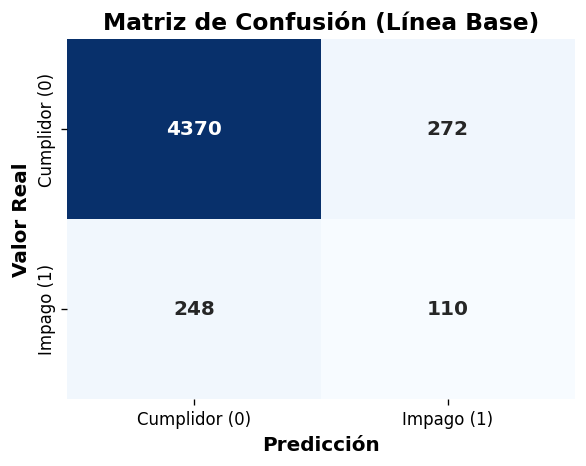

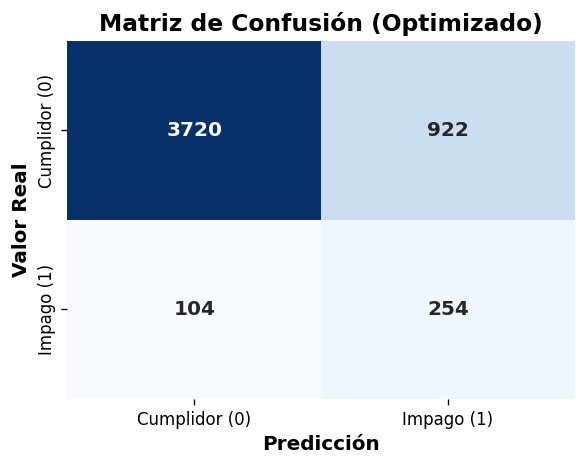

In [ ]:
view_matrix(y_test, y_pred_base, "Línea Base")
view_matrix(y_test, y_pred_opt, "Optimizado")

In [ ]:
# Cuantificación del impacto financiero real a partir de las Matrices de Confusión
cm_b = confusion_matrix(y_test, y_pred_base)
cm_o = confusion_matrix(y_test, y_pred_opt)

tn_b, fp_b, fn_b, tp_b = cm_b.ravel()
tn_o, fp_o, fn_o, tp_o = cm_o.ravel()

cost_fn_unit = 1_500_000  # Pérdida directa por cada crédito otorgado que termina en impago
cost_fp_unit = 200_000    # Costo de oportunidad por denegar un crédito viable

cost_fn_base = fn_b * cost_fn_unit
cost_fp_base = fp_b * cost_fp_unit
total_cost_base = cost_fn_base + cost_fp_base

cost_fn_opt = fn_o * cost_fn_unit
cost_fp_opt = fp_o * cost_fp_unit
total_cost_opt = cost_fn_opt + cost_fp_opt
ahorro_neto = total_cost_base - total_cost_opt

print(f"""===========================================================================
IMPACTO FINANCIERO EN EL CONJUNTO DE PRUEBA (5.000 SOLICITUDES HIPOTECARIAS)
===========================================================================
Supuestos de negocio:
- Costo por Falso Negativo (FN - Crédito otorgado que cae en impago): $1.500.000
- Costo por Falso Positivo (FP - Crédito viable denegado / interés perdido): $200.000

1. MODELO LÍNEA BASE:
   - Verdaderos Negativos (VN = {tn_b:,}): Clientes cumplidores aprobados correctamente.
   - Verdaderos Positivos (VP = {tp_b:,}): Clientes morosos detectados a tiempo (evita ${tp_b * cost_fn_unit:,.0f} en pérdidas).
   - Falsos Negativos     (FN = {fn_b:,}): Créditos impagos otorgados -> Pérdida directa: ${cost_fn_base:,.0f}
   - Falsos Positivos     (FP = {fp_b:,}): Clientes cumplidores rechazados -> Costo oportunidad: ${cost_fp_base:,.0f}
   -> COSTO FINANCIERO TOTAL (LÍNEA BASE): ${total_cost_base:,.0f}

2. MODELO OPTIMIZADO (DecisionTreeClassifier + GridSearchCV):
   - Verdaderos Negativos (VN = {tn_o:,}): Clientes cumplidores aprobados correctamente.
   - Verdaderos Positivos (VP = {tp_o:,}): Clientes morosos detectados a tiempo (evita ${tp_o * cost_fn_unit:,.0f} en pérdidas).
   - Falsos Negativos     (FN = {fn_o:,}): Créditos impagos otorgados -> Pérdida directa: ${cost_fn_opt:,.0f}
   - Falsos Positivos     (FP = {fp_o:,}): Clientes cumplidores rechazados -> Costo oportunidad: ${cost_fp_opt:,.0f}
   -> COSTO FINANCIERO TOTAL (OPTIMIZADO): ${total_cost_opt:,.0f}

===========================================================================
CONCLUSIÓN FINANCIERA:
- Reducción de créditos en impago otorgados (FN): de {fn_b} a {fn_o} (-{fn_b - fn_o} impagos = ahorro de capital de ${(fn_b - fn_o)*cost_fn_unit:,.0f}).
- AHORRO NETO PARA LA INSTITUCIÓN FINANCIERA: ${ahorro_neto:,.0f} (-{ahorro_neto / total_cost_base * 100:.2f}% del costo total).
===========================================================================""")

IMPACTO FINANCIERO EN EL CONJUNTO DE PRUEBA (5.000 SOLICITUDES HIPOTECARIAS)
Supuestos de negocio:
- Costo por Falso Negativo (FN - Crédito otorgado que cae en impago): $1.500.000
- Costo por Falso Positivo (FP - Crédito viable denegado / interés perdido): $200.000

1. MODELO LÍNEA BASE:
   - Verdaderos Negativos (VN = 4,370): Clientes cumplidores aprobados correctamente.
   - Verdaderos Positivos (VP = 110): Clientes morosos detectados a tiempo (evita $165,000,000 en pérdidas).
   - Falsos Negativos     (FN = 248): Créditos impagos otorgados -> Pérdida directa: $372,000,000
   - Falsos Positivos     (FP = 272): Clientes cumplidores rechazados -> Costo oportunidad: $54,400,000
   -> COSTO FINANCIERO TOTAL (LÍNEA BASE): $426,400,000

2. MODELO OPTIMIZADO (DecisionTreeClassifier + GridSearchCV):
   - Verdaderos Negativos (VN = 3,720): Clientes cumplidores aprobados correctamente.
   - Verdaderos Positivos (VP = 254): Clientes morosos detectados a tiempo (evita $381,000,000 en pérdidas).


### Interpretación Detallada de las Matrices de Confusión en el Contexto Bancario

| Indicador / Cuadrante | Modelo Línea Base | Modelo Optimizado | Interpretación en el Negocio Hipotecario |
| :--- | :---: | :---: | :--- |
| **Verdaderos Negativos ($VN$)** | `4.370` | `3.720` | Clientes solventes a quienes se les aprueba el crédito correctamente, generando ingresos por intereses. |
| **Falsos Positivos ($FP$)** | `272` | `922` | Clientes cumplidores clasificados por error como riesgosos (**Costo de oportunidad: `$200.000` c/u**). Sube de **`$54.400.000`** (Base) a **`$184.400.000`** (Optimizado) al aplicar una política de evaluación más estricta. |
| **Falsos Negativos ($FN$)** | `248` | `104` | **El error más grave para el banco:** clientes morosos aprobados como cumplidores (**Pérdida directa: `$1.500.000` c/u**). Se logra reducir los impagos otorgados de `248` a `104` (**144 impagos menos**), bajando la pérdida de capital de **`$372.000.000`** a **`$156.000.000`** (un ahorro directo de **`$216.000.000`**). |
| **Verdaderos Positivos ($VP$)** | `110` | `254` | Clientes morosos detectados a tiempo (**el *Recall* sube de `30,73%` a `70,95%` y el *F1-Score* mejora de `29,73%` a `33,12%`**), evitando pérdidas de capital por **`$381.000.000`**. |
| **Costo Total del Error ($FN + FP$)** | **`$426.400.000`** | **`$340.400.000`** | **Se obtiene un ahorro neto de `$86.000.000` (reducción del `20,17%` en los costos de error)** evaluando las `5.000` solicitudes de prueba. |

1. **Desempeño del Modelo Línea Base:** Al entrenarse sin límite de profundidad ni balanceo de pesos (`class_weight=None`), el árbol memoriza el conjunto de entrenamiento (`Recall = 1,0000` y `F1-Score = 1,0000` en *train*), pero pierde capacidad de generalización ante datos nuevos: solo detecta **110 de los 358 impagos reales (`Recall = 30,73%`, `F1-Score = 29,73%`)**, dejando pasar **248 créditos fallidos (`FN`)** que representan **`$372.000.000`** en pérdidas directas de capital y un costo total de **`$426.400.000`**.
2. **Desempeño del Modelo Optimizado (`entropy`, `max_depth=6`, `min_samples_leaf=10`, `min_samples_split=5`, `class_weight='balanced'`):** Al compensar el peso de la clase minoritaria y limitar la profundidad máxima a 6 niveles, se frena la memorización y el modelo generaliza mejor: captura **254 de los 358 impagos (`Recall = 70,95%`)**, eleva el **F1-Score a `33,12%`** y reduce los Falsos Negativos a **104 casos (`$156.000.000`)**. Aunque esta postura preventiva aumenta los Falsos Positivos a **922 solicitudes rechazadas (`$184.400.000` en costo de oportunidad)** —casos que en la práctica bancaria pueden pasar a una segunda evaluación manual o exigencia de garantías adicionales—, el balance económico resulta muy favorable: **se ahorran `$216.000.000` en pérdidas de capital a cambio de `$130.000.000` adicionales en costo de oportunidad**, logrando un **ahorro neto de `$86.000.000`** para la institución.

## 4.3 Curva ROC-AUC Comparativa

A modo de comparación visual entre el Modelo Línea Base y el Modelo Optimizado con `GridSearchCV`, se grafica la **Curva ROC** (que relaciona la *Tasa de Verdaderos Positivos / Recall* en el eje vertical frente a la *Tasa de Falsos Positivos* en el eje horizontal):
- **Línea punteada negra (`AUC = 0,50`):** Representa un clasificador aleatorio (equivalente a decidir al azar).
- **Línea naranja (`Línea Base, AUC = 0,6243`):** Al memorizar los datos de entrenamiento sin restricción de profundidad, el árbol base tiene una baja capacidad para distinguir entre clientes cumplidores y morosos en el conjunto de prueba.
- **Línea verde (`Optimizado con GridSearchCV, AUC = 0,8315`):** Al regularizar el árbol y balancear los pesos de clase, la curva se acerca a la esquina superior izquierda, demostrando que el modelo optimizado logra un *Recall* mucho más alto con una mejor separación entre ambos perfiles de clientes.

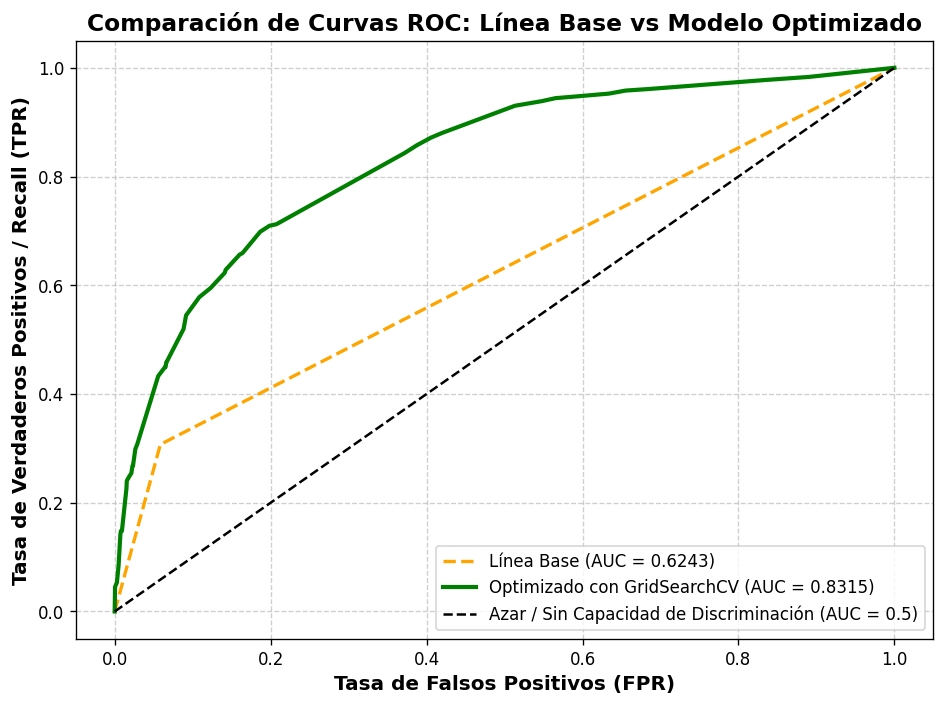

In [ ]:
fpr_base, tpr_base, _ = roc_curve(y_test, y_proba_base)
fpr_opt, tpr_opt, _ = roc_curve(y_test, y_proba_opt)

plt.figure(figsize=(8, 6))
plt.plot(
    fpr_base,
    tpr_base,
    label=f"Línea Base (AUC = {auc_base:.4f})",
    color="orange",
    linestyle="--",
    linewidth=2,
)
plt.plot(
    fpr_opt,
    tpr_opt,
    label=f"Optimizado con GridSearchCV (AUC = {auc_opt:.4f})",
    color="green",
    linewidth=2.5,
)
plt.plot([0, 1], [0, 1], "k--", label="Azar / Sin Capacidad de Discriminación (AUC = 0.5)")

plt.xlabel("Tasa de Falsos Positivos (FPR)", fontsize=12, fontweight="bold")
plt.ylabel("Tasa de Verdaderos Positivos / Recall (TPR)", fontsize=12, fontweight="bold")
plt.title("Comparación de Curvas ROC: Línea Base vs Modelo Optimizado", fontsize=14, fontweight="bold")
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

## 4.4 Visualización del Árbol de Decisión Optimizado e Importancia de Variables

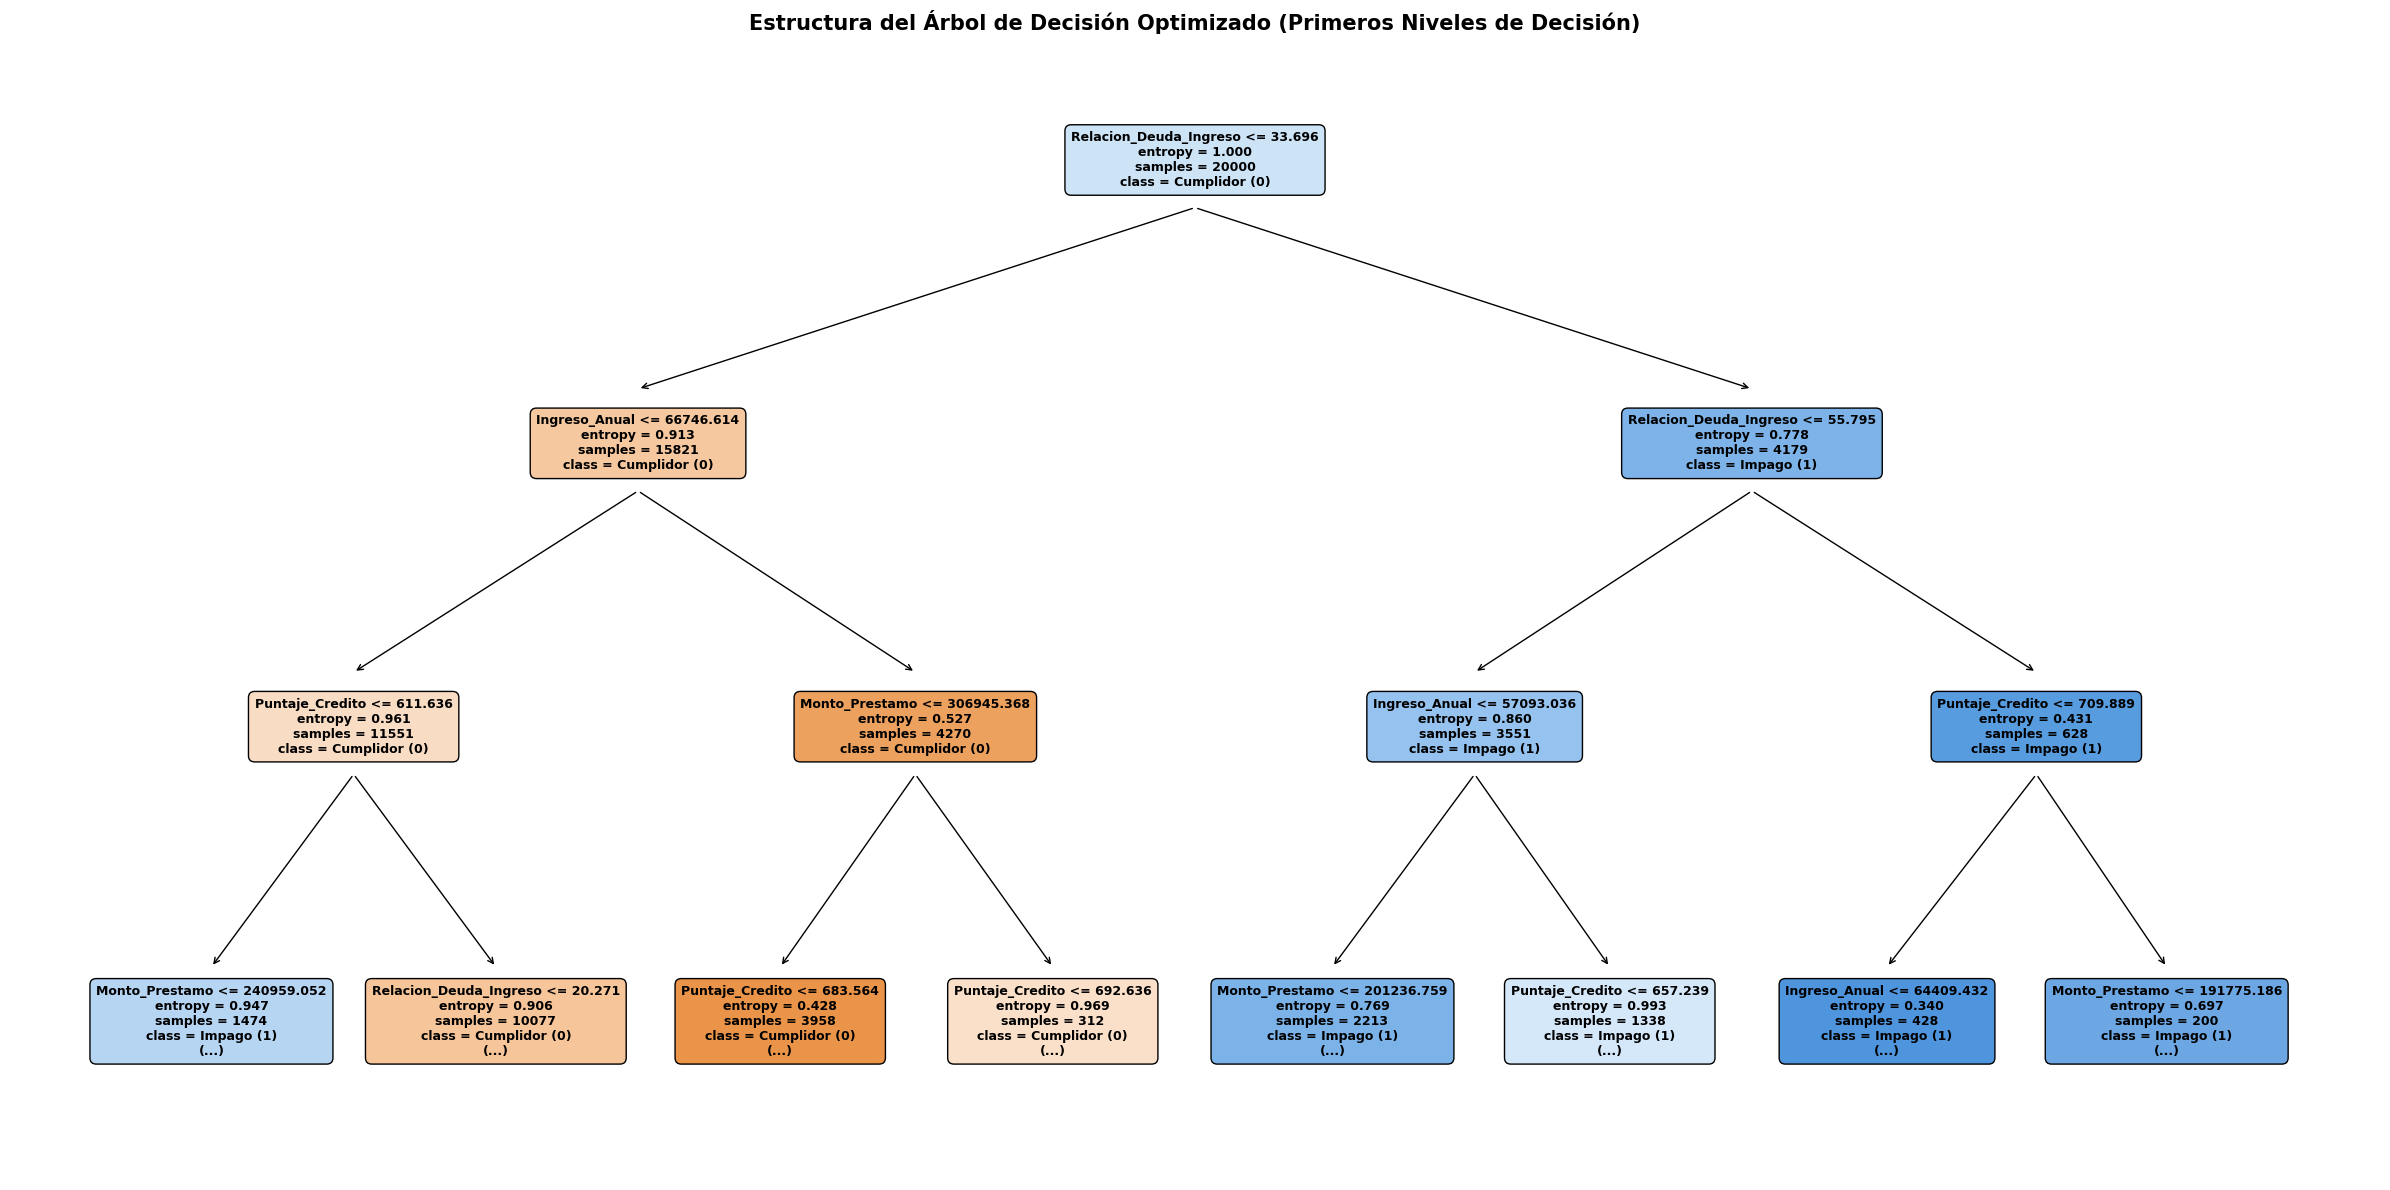

In [ ]:
# Visualización de los primeros niveles del Árbol de Decisión Optimizado para facilitar su lectura ejecutiva
plt.figure(figsize=(24, 12))
plot_tree(
    best_tree,
    max_depth=3,
    feature_names=numeric_features,
    class_names=target_names,
    filled=True,
    rounded=True,
    fontsize=9,
)
plt.title("Estructura del Árbol de Decisión Optimizado (Primeros Niveles de Decisión)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
# Extracción de la importancia relativa de cada variable para el negocio
importances = best_tree.feature_importances_
feature_imp_df = pd.DataFrame({
    "Variable": numeric_features,
    "Importancia": importances
}).sort_values(by="Importancia", ascending=False)

feature_imp_df

,Variable,Importancia
3,Relacion_Deuda_Ingreso,0.556739
2,Puntaje_Credito,0.167726
0,Ingreso_Anual,0.157807
1,Monto_Prestamo,0.117728


In [ ]:
# Verifica que la suma de las importancias sea igual a 1.0
np.sum(importances)

np.float64(1.0)


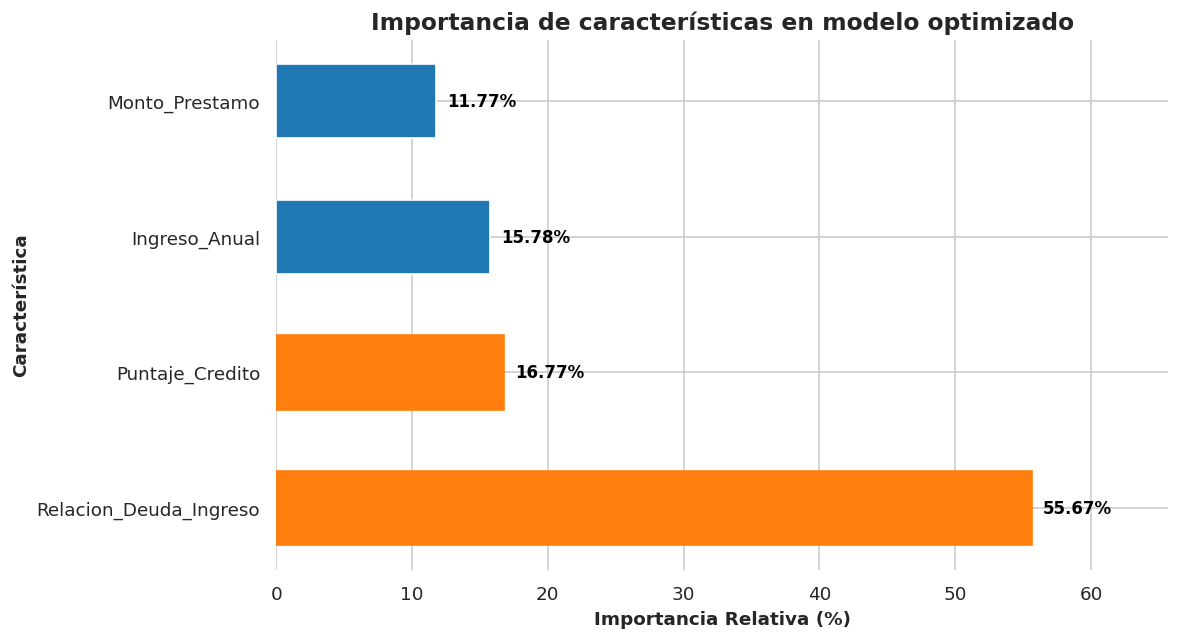

In [ ]:
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(10, 5.5))

primary_color = "#1f77b4"
highlight_color = "#ff7f0e"
text_color = "#000000"

bars = ax.barh(feature_imp_df["Variable"], feature_imp_df["Importancia"] * 100, color=primary_color, height=0.55)

# Destaca las 2 variables más determinantes para el riesgo crediticio
bars[0].set_color(highlight_color)
bars[1].set_color(highlight_color)

for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.8, bar.get_y() + bar.get_height()/2, f"{width:.2f}%",
            va="center", ha="left", fontsize=10, fontweight="bold", color=text_color)

ax.set_title("Importancia de características en modelo optimizado", fontsize=14, fontweight="bold")
ax.set_xlabel("Importancia Relativa (%)", fontsize=11, fontweight="bold")
ax.set_xlim(0, max(feature_imp_df["Importancia"]) * 100 + 10)

sns.despine(left=True, bottom=True)
ax.set_ylabel("Característica", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

### Interpretación de Importancia de Variables para Comité de Riesgo

1. **`Relacion_Deuda_Ingreso` (`55,67%` de importancia):** Es el factor dominante en la decisión del árbol. Cuando un solicitante compromete un alto porcentaje de su ingreso mensual en deudas vigentes ($DTI$ elevado), su capacidad de absorber la cuota hipotecaria cae drásticamente, disparando la probabilidad de impago.
2. **`Puntaje_Credito` (`16,77%` de importancia):** Actúa como el segundo filtro clave de solvencia histórica; puntajes bajos reflejan morosidades previas y elevan el riesgo incluso en solicitantes con ingresos medios.
3. **`Ingreso_Anual` (`15,78%` de importancia) y `Monto_Prestamo` (`11,77%` de importancia):** Complementan la evaluación midiendo el respaldo patrimonial del cliente frente al tamaño del capital hipotecario solicitado.